In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

datos = pd.read_csv('../../data/silver/cleaned_houses_inmuebles_v3.csv')
datos.info()


<class 'pandas.DataFrame'>
RangeIndex: 532 entries, 0 to 531
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Total_area_m2     532 non-null    int64  
 1   Built_area_m2     532 non-null    int64  
 2   Rooms             532 non-null    int64  
 3   Bathrooms         532 non-null    int64  
 4   HalfBathrooms     532 non-null    int64  
 5   Parkings          532 non-null    int64  
 6   Colonia           532 non-null    str    
 7   Price             532 non-null    int64  
 8   Maintenance_cost  532 non-null    int64  
 9   PropertyType      532 non-null    str    
 10  Latitude          532 non-null    float64
 11  Longitude         532 non-null    float64
dtypes: float64(2), int64(8), str(2)
memory usage: 50.0 KB


In [2]:
from sklearn.model_selection import train_test_split

x = datos.drop(columns=['Price'])
y = datos['Price']

x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.8, random_state=777, shuffle=True)
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from category_encoders import TargetEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np

coordenadas = ['Latitude', 'Longitude']
areas = ['Total_area_m2', 'Built_area_m2']
categoricos_property = ['PropertyType']
categoricos_colonias = ['Colonia']

preprocessor = ColumnTransformer(
    transformers=[
        ('coordenadas',MinMaxScaler(),coordenadas),
        ('areas',PowerTransformer(method='box-cox', standardize=True),areas),
        ('categoricos_property',OneHotEncoder(handle_unknown='ignore'),categoricos_property),
        ('categoricos_colonias',TargetEncoder(smoothing=10.0), categoricos_colonias)
    ],
    remainder='passthrough'
)
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from scipy.stats import uniform, randint

modelos = {
    'Ridge': Ridge(random_state=777),
    'Lasso': Lasso(random_state=777),
    'ElasticNet': ElasticNet(random_state=777),
    'RandomForest': RandomForestRegressor(random_state=777),
    'XGBoost': XGBRegressor(random_state=777, objective='reg:squarederror'),
    'CatBoost': CatBoostRegressor(random_state=777, verbose=False),
    'LightGBM': LGBMRegressor(random_state=777, verbose=-1)
}

parametros = {
    'Ridge': {'model__alpha': uniform(0.1, 10.0)},
    'Lasso': {'model__alpha': uniform(0.01, 1.0)},
    'ElasticNet': {'model__alpha': uniform(0.01, 1.0), 'model__l1_ratio': uniform(0.0, 1.0)},
    'RandomForest': {'model__n_estimators': randint(50, 200), 'model__max_depth': [None, 10, 20]},
    'XGBoost': {'model__n_estimators': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__max_depth': randint(3, 8)},
    'CatBoost': {'model__iterations': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__depth': randint(4, 8)},
    'LightGBM': {'model__n_estimators': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__num_leaves': randint(20, 100)}
}

# 5. Entrenamiento y evaluación
mejores_modelos = {}
resultados = []
cv = KFold(n_splits=5, shuffle=True, random_state=777)


for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")
    
    # Crear Pipeline: preprocesamiento de X y regresor sobre el precio original
    pipeline = Pipeline([
        ('preprocesador', preprocessor),
        ('model', modelo)
    ])
    
    # Random Search CV
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros[nombre],
        n_iter=50, # Ajusta este valor según tu capacidad de cómputo (10 a 50 es ideal)
        cv=cv,
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        random_state=777
    )
    
    # Entrenar
    random_search.fit(x_train, y_train)
    mejor_modelo = random_search.best_estimator_
    mejores_modelos[nombre] = mejor_modelo
    
    # Predicciones
    y_pred = mejor_modelo.predict(x_test)
    
    # Métricas
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # R2 Ajustado
    n = len(y_test)
    p = x_test.shape[1]
    r2_adj = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    
    resultados.append({
        'Modelo': nombre,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R2': r2,
        'R2 Ajustado': r2_adj,
        'Mejores Params': str(random_search.best_params_)
    })

# 6. Mostrar tabla de rendimiento
df_resultados = pd.DataFrame(resultados)
# Ordenamos por RMSE (el valor más bajo es mejor)
df_resultados = df_resultados.sort_values(by='RMSE', ascending=True).reset_index(drop=True)

print("\n--- Rendimiento de los Modelos ---")
# Mostrar en consola de forma tabulada (requiere librería 'tabulate', o se imprime directo)
print(df_resultados[['Modelo', 'MAE', 'RMSE', 'MAPE', 'R2', 'R2 Ajustado']].to_string(index=False))

# 7. Seleccionar el mejor
mejor_nombre = df_resultados.iloc[0]['Modelo']
mejor_r2 = df_resultados.iloc[0]['R2']
print(f"\nEl mejor modelo es: {mejor_nombre} con un R2 de {mejor_r2:.4f}")

Entrenando Ridge...
Entrenando Lasso...
Entrenando ElasticNet...


d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.187874e+15, tolerance: 8.310e+11
  model = cd_fast.enet_coordinate_descent(


Entrenando RandomForest...
Entrenando XGBoost...
Entrenando CatBoost...
Entrenando LightGBM...

--- Rendimiento de los Modelos ---
      Modelo          MAE         RMSE     MAPE        R2  R2 Ajustado
RandomForest 9.667874e+05 1.504329e+06 0.175364  0.849868     0.832485
     XGBoost 1.088802e+06 1.617105e+06 0.200699  0.826514     0.806427
    LightGBM 1.117521e+06 1.672920e+06 0.192589  0.814332     0.792834
    CatBoost 1.121523e+06 1.751312e+06 0.198060  0.796524     0.772963
  ElasticNet 1.784010e+06 2.756997e+06 0.361489  0.495734     0.437346
       Ridge 2.294463e+06 7.430900e+06 0.431003 -2.663275    -3.087444
       Lasso 2.540263e+06 9.908747e+06 0.464600 -5.513647    -6.267859

El mejor modelo es: RandomForest con un R2 de 0.8499


In [3]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate

# Seleccionar el mejor modelo
mejor_nombre = df_resultados.iloc[0]['Modelo']
mejor_modelo = mejores_modelos[mejor_nombre]

print(f"Modelo seleccionado: {mejor_nombre}")

# Validación cruzada
cv = KFold(n_splits=5, shuffle=True, random_state=777)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'R2': 'r2'
}

resultados_cv = cross_validate(
    estimator=mejor_modelo,
    X=x_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Construir tabla de métricas por fold
df_folds = pd.DataFrame({
    'Fold': np.arange(1, 6),

    'MAE_Train': -resultados_cv['train_MAE'],
    'MAE_Validacion': -resultados_cv['test_MAE'],

    'RMSE_Train': np.sqrt(-resultados_cv['train_MSE']),
    'RMSE_Validacion': np.sqrt(-resultados_cv['test_MSE']),

    'R2_Train': resultados_cv['train_R2'],
    'R2_Validacion': resultados_cv['test_R2']
})

# Brechas entre entrenamiento y validación
df_folds['Brecha_RMSE'] = (
    df_folds['RMSE_Validacion'] - df_folds['RMSE_Train']
)

df_folds['Brecha_R2'] = (
    df_folds['R2_Train'] - df_folds['R2_Validacion']
)

print("\nMétricas por fold:")
print(df_folds.round(4).to_string(index=False))

Modelo seleccionado: RandomForest

Métricas por fold:
 Fold   MAE_Train  MAE_Validacion  RMSE_Train  RMSE_Validacion  R2_Train  R2_Validacion  Brecha_RMSE  Brecha_R2
    1 476172.2184    1066914.6809 795134.3190     1538947.6400    0.9695         0.8406  743813.3210     0.1289
    2 429124.0966    1347508.0236 715048.0783     2183899.2411    0.9738         0.7590 1468851.1627     0.2147
    3 420111.8546    1893270.2086 636987.0554     3218301.7798    0.9739         0.7001 2581314.7244     0.2738
    4 430950.6246    1102370.7750 681594.1561     1779969.9570    0.9780         0.7520 1098375.8009     0.2260
    5 457264.1276     965514.0564 744231.3183     1564963.3227    0.9733         0.8288  820732.0044     0.1445


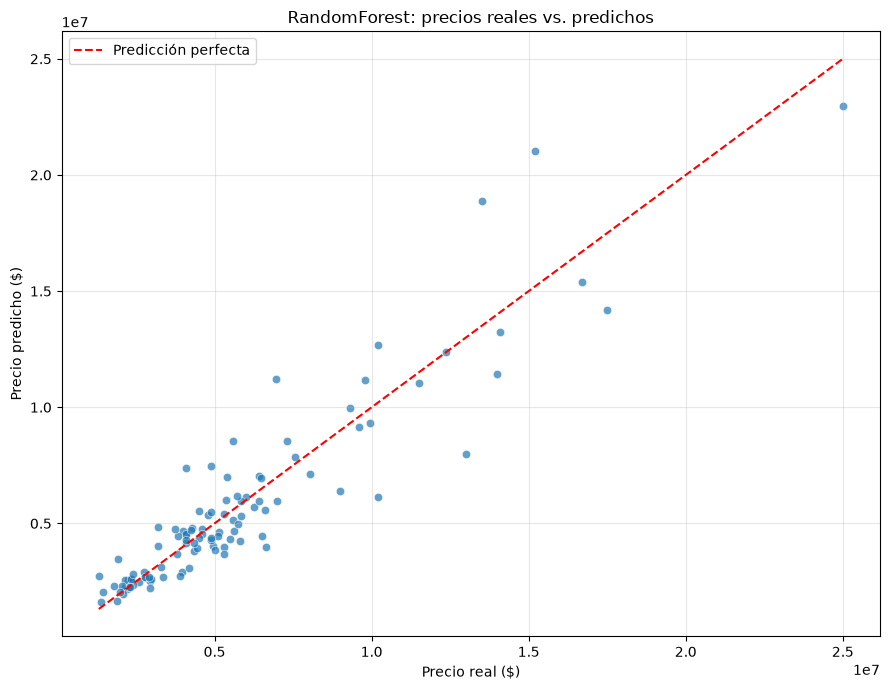

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

modelo_catBoost = mejores_modelos['RandomForest']

y_pred = modelo_catBoost.predict(x_test)

resultados_casas = x_test.copy()

resultados_casas['Precio_real'] = np.asarray(y_test)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=resultados_casas,
    x='Precio_real',
    y='Precio_predicho',
    alpha=0.7
)

limite_min = min(
    resultados_casas['Precio_real'].min(),
    resultados_casas['Precio_predicho'].min()
)

limite_max = max(
    resultados_casas['Precio_real'].max(),
    resultados_casas['Precio_predicho'].max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--',
    color='red',
    label='Predicción perfecta'
)

plt.xlabel('Precio real ($)')
plt.ylabel('Precio predicho ($)')
plt.title('RandomForest: precios reales vs. predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


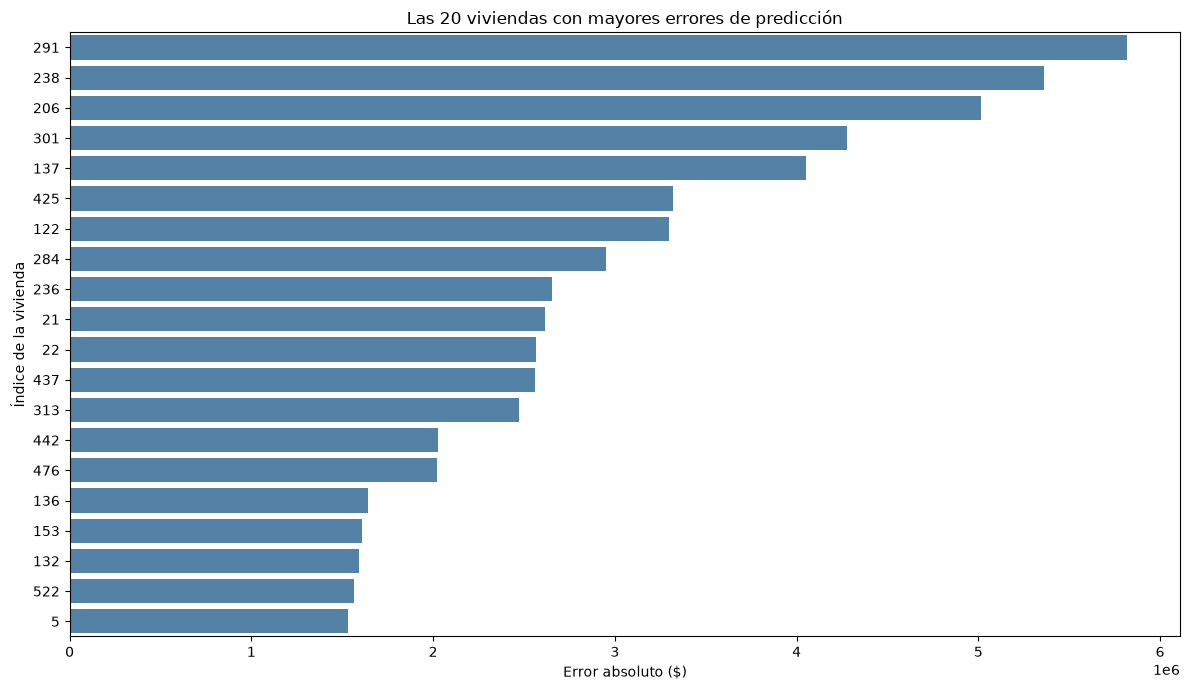

In [5]:
# Unir información original con resultados
resultados_casas = datos.loc[x_test.index].copy()

resultados_casas['Precio_real'] = np.asarray(y_test)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

# Seleccionar las 20 viviendas con mayores errores
peores_casas = resultados_casas.nlargest(20, 'Error_absoluto')

# Visualización
plt.figure(figsize=(12, 7))

sns.barplot(
    data=peores_casas,
    x='Error_absoluto',
    y=peores_casas.index.astype(str),
    color='steelblue'
)

plt.xlabel('Error absoluto ($)')
plt.ylabel('Índice de la vivienda')
plt.title('Las 20 viviendas con mayores errores de predicción')
plt.tight_layout()
plt.show()